# LightGBM baseline (modelling plan, Phase 4, first pass)

A plain, **untuned** LightGBM on the account-week table, to see how far the 64 inputs get before any tuning.
Hyperparameter tuning comes later; here every setting is LightGBM's default except class weights and a seed.

| § | What |
|---|---|
| 0 | Setup: find the repo, pick the data folder |
| 1 | Build the account-week table (features + label) |
| 2 | The three views: application, activity, combined |
| 3 | Class weights |
| 4 | Three temporal folds: train, score |
| 5 | Results: AUCs, precision, recall, F1 |
| 6 | Figures |
| 7 | By week since opening, and feature importance |
| 8 | Save the report |

**Rules kept.** Labels come only through `amldata.labels()`; months 0 to 4 only (month 5 stays for calibration,
months 6 to 7 stay closed); no hidden file is read. The loading and metric functions live in
`src/models/lgbm_baseline.py` so the script and this notebook always compute the same numbers.

**How to run.** Open in VS Code and Run All (uses `data/v1_full`). For the quick 50k set, set the environment
variable `EDA_DATA=data/v1` before starting, or edit `OUT` in the next cell.

In [1]:
from __future__ import annotations
import json, os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# find the repo root (the folder holding src/amldata) so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import lightgbm as lgb
import amldata
from features.weekly import FEATURES as WEEKLY
from models.lgbm_baseline import load_table, profiles, evaluate, by_week, figures, write_report, FOLDS, KEY

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)     # data/v1_full by default
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", f"outputs/modelling/models/{RUN}/lgbm_baseline"))
REPORT.mkdir(parents=True, exist_ok=True)
WEEKS = (0, 26)        # main horizon, weeks since opening
SEED = 42
DROP: list[str] = []   # e.g. ["weeks_since_open"] for the ablation
print(f"data {OUT} -> report {REPORT} | lightgbm {lgb.__version__}")

data data/v1_full -> report outputs/modelling/models/v1_full/lgbm_baseline | lightgbm 4.7.0


## 1. The account-week table

One row per account per week since opening (weeks 0 to 26), for accounts opened in months 0 to 4.

- **Features**: the cleaned application table (`features/accounts_tree.parquet`, 35 columns) joined to the
  weekly feature store (`features/weekly.parquet`, 28 columns), plus `weeks_since_open`.
- **Label**: `mule_by_day` at the end of each account's week: a fake account counts as a mule from opening,
  a real customer from the week laundering starts (team decision 8 Oct).
- **Dropped**: weeks after the bank closed the account (`open_by_day = 0`); a closed account has no activity,
  which would give the label away.

In [2]:
t0 = time.time()
df, APP = load_table(OUT, (0, 1, 2, 3, 4), WEEKS)
prof = profiles(OUT, (0, 1, 2, 3, 4))     # hidden type, used only to break results down, never a feature
print(f"{len(df):,} account-weeks in {time.time() - t0:.0f}s")
df.groupby("open_month").agg(accounts=("account_id", "nunique"), account_weeks=("account_id", "size"),
                             mule_weeks=("mule_by_day", "sum"), mule_rate=("mule_by_day", "mean"))

4,449,169 account-weeks in 4s


,accounts,account_weeks,mule_weeks,mule_rate
open_month,,,,
0,32217,869599,1926,0.002215
1,31076,838843,1592,0.001898
2,33523,904948,1473,0.001628
3,36724,991390,1564,0.001578
4,31279,844389,1772,0.002099


## 2. Three views

The project's question is whether application data adds anything to activity data, so the same model is trained
three times on the same rows:

| view | inputs | count |
|---|---|---|
| application | 29 BAF columns + 6 missing flags | 35 |
| activity | 28 weekly features + `weeks_since_open` | 29 |
| combined | both | 64 |

In [3]:
VIEWS = {"application": APP,
         "activity": WEEKLY + ["weeks_since_open"],
         "combined": APP + WEEKLY + ["weeks_since_open"]}
VIEWS = {k: [c for c in v if c not in DROP] for k, v in VIEWS.items()}
{k: len(v) for k, v in VIEWS.items()}

{'application': 35, 'activity': 29, 'combined': 64}

## 3. Class weights

Only about 0.3% of account-weeks are mule weeks. A model that never flags anyone would be 99.7% accurate and
useless. `class_weight="balanced"` gives each class the weight

$$w_c = \frac{n}{2\,n_c}\qquad\Rightarrow\qquad \frac{w_{\text{mule}}}{w_{\text{normal}}} = \frac{1-p}{p}$$

where $p$ is the share of mule rows. Missing one mule week then costs the model as much as wrongly flagging
$\frac{1-p}{p}$ normal weeks (computed below). Side effect: scores are pushed up and are no longer probabilities,
so a 0.5 cut-off flags far too many accounts; calibration on month 5 is a later step.

In [4]:
p = df["mule_by_day"].mean()
print(f"share of mule rows p = {p:.4%};  weight ratio (1-p)/p = {(1 - p) / p:,.0f}")

share of mule rows p = 0.1872%;  weight ratio (1-p)/p = 533


## 4. Three temporal folds

Expanding window by **opening month**. An account opens in one month only, so its weeks never sit on both sides,
and each fold mimics the real test: score customers the model has never seen.

| fold | train on months | validate on month |
|---|---|---|
| 1 | 0, 1 | 2 |
| 2 | 0, 1, 2 | 3 |
| 3 | 0, 1, 2, 3 | 4 |

Only three folds because each month holds about 90 launderers; smaller validation sets would make the metrics
too noisy.

In [5]:
fold_rows, oof, imps = [], [], []
for f, (train_m, valid_m) in enumerate(FOLDS, start=1):
    train, valid = df[df.open_month.isin(train_m)], df[df.open_month == valid_m]
    for name, cols in VIEWS.items():
        model = lgb.LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1,
                                   deterministic=True, force_row_wise=True)   # same result every run
        model.fit(train[cols], train["mule_by_day"])
        score = model.predict_proba(valid[cols])[:, 1]
        m = evaluate(valid, score, prof)
        fold_rows.append({"fold": f, "train_months": "-".join(map(str, train_m)), "valid_month": valid_m,
                          "view": name, "features": len(cols), **m})
        oof.append(valid[KEY + ["mule_by_day"]].assign(score=score, view=name, fold=f))
        g = model.booster_.feature_importance("gain")
        imps.append(pd.DataFrame({"feature": cols, "gain": g, "share": g / g.sum(), "view": name, "fold": f}))
    print(f"fold {f} done: train {train_m} -> valid {valid_m}")
folds = pd.concat([pd.DataFrame(fold_rows)], ignore_index=True)
oof = pd.concat(oof, ignore_index=True)
imp = pd.concat(imps, ignore_index=True)

fold 1 done: train (0, 1) -> valid 2


fold 2 done: train (0, 1, 2) -> valid 3


fold 3 done: train (0, 1, 2, 3) -> valid 4


## 5. Results

**Account level**: an account's highest weekly score in weeks 0 to 26, against whether it was ever a mule in
that horizon. That is the unit a bank reviews.

Precision, recall and F1 need a cut-off ("flag if the score is above X"), so they are given at three:

| cut-off | meaning | use |
|---|---|---|
| @0.5 | flag if score ≥ 0.5 | textbook default; with class weights it flags far too many |
| @best | the threshold with the best F1 on that fold | optimistic: chosen on the data it is scored on |
| top 1% | flag the 1% highest-scoring accounts | **the one to report**: a fixed review budget |

$$\text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

PR-AUC is the headline number when positives are this rare: chance level equals the mule share (about 0.003),
while ROC-AUC looks high easily.

In [6]:
cols = {"acc_roc_auc": "ROC-AUC", "acc_pr_auc": "PR-AUC",
        "acc_at_0.5_precision": "P @0.5", "acc_at_0.5_recall": "R @0.5", "acc_at_0.5_f1": "F1 @0.5",
        "acc_best_f1_precision": "P @best", "acc_best_f1_recall": "R @best", "acc_best_f1_f1": "F1 @best",
        "acc_top_1%_precision": "P top 1%", "acc_top_1%_recall": "R top 1%", "acc_top_1%_f1": "F1 top 1%"}
summary = folds.groupby("view", sort=False)[list(cols)].mean().rename(columns=cols)
summary.round(3)

,ROC-AUC,PR-AUC,P @0.5,R @0.5,F1 @0.5,P @best,R @best,F1 @best,P top 1%,R top 1%,F1 top 1%
view,,,,,,,,,,,
application,0.743,0.011,0.017,0.115,0.028,0.052,0.106,0.051,0.020,0.092,0.033
activity,0.989,0.730,0.003,0.996,0.005,0.797,0.668,0.724,0.181,0.871,0.300
combined,0.953,0.256,0.040,0.715,0.073,0.375,0.289,0.322,0.112,0.526,0.185


Each fold separately, with how many mules of each hidden type landed in the top 1% (caught / all of that type):

In [7]:
folds[["fold", "train_months", "valid_month", "view", "accounts", "account_mules", "acc_pr_auc",
       "acc_top_1%_precision", "acc_top_1%_recall", "acc_top_1%_f1",
       "top_1%_fake", "top_1%_witting", "top_1%_unwitting"]].round(3)

,fold,train_months,valid_month,view,accounts,account_mules,acc_pr_auc,acc_top_1%_precision,acc_top_1%_recall,acc_top_1%_f1,top_1%_fake,top_1%_witting,top_1%_unwitting
0,1,0-1,2,application,33523,64,0.012,0.009,0.047,0.015,3/56,0/3,0/5
1,1,0-1,2,activity,33523,64,0.672,0.164,0.859,0.276,49/56,2/3,4/5
2,1,0-1,2,combined,33523,64,0.193,0.084,0.438,0.140,25/56,2/3,1/5
3,2,0-1-2,3,application,36724,70,0.007,0.014,0.071,0.023,5/57,0/7,0/6
4,2,0-1-2,3,activity,36724,70,0.751,0.169,0.886,0.284,50/57,6/7,6/6
5,2,0-1-2,3,combined,36724,70,0.173,0.084,0.443,0.142,28/57,1/7,2/6
6,3,0-1-2-3,4,application,31279,76,0.016,0.038,0.158,0.062,12/65,0/4,0/7
7,3,0-1-2-3,4,activity,31279,76,0.767,0.211,0.868,0.339,59/65,1/4,6/7
8,3,0-1-2-3,4,combined,31279,76,0.404,0.169,0.697,0.272,47/65,1/4,5/7


## 6. Figures

1. Precision-recall curve (account level, all three validation months pooled), with the chance line.
2. ROC curve.
3. PR-AUC and top-1% precision, recall, F1: bar = mean of 3 folds, dots = each fold.
4. By week since opening: how well that week's ranking works; shaded band = weeks 8 to 17, when fakes start laundering.
5. Top 15 features by gain in the combined model.

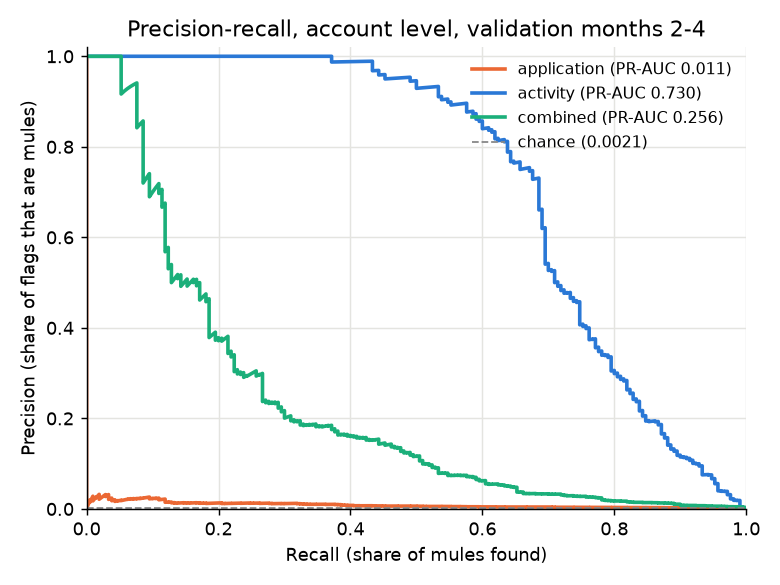

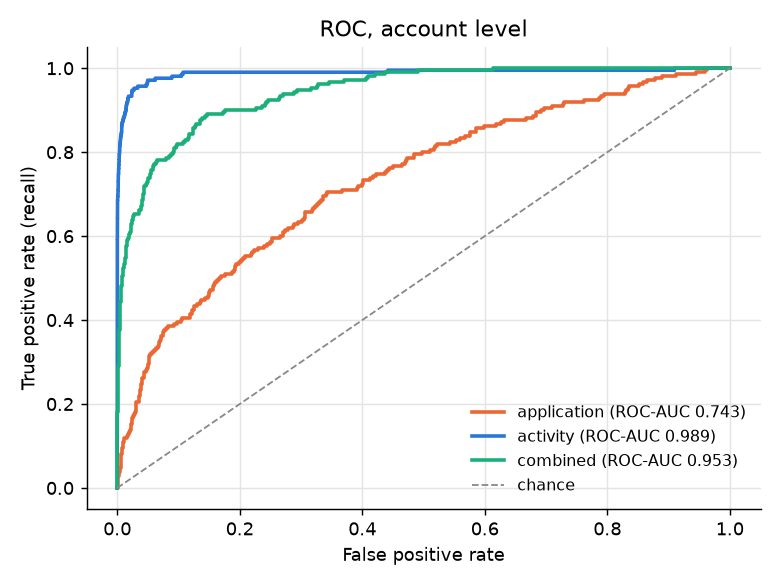

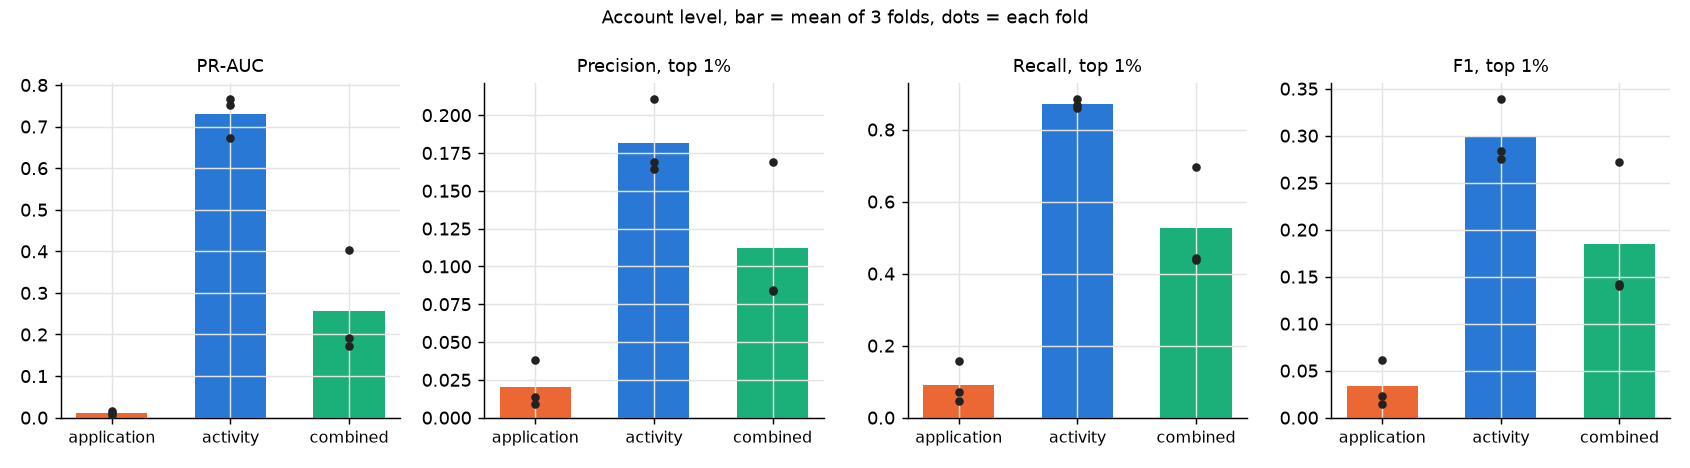

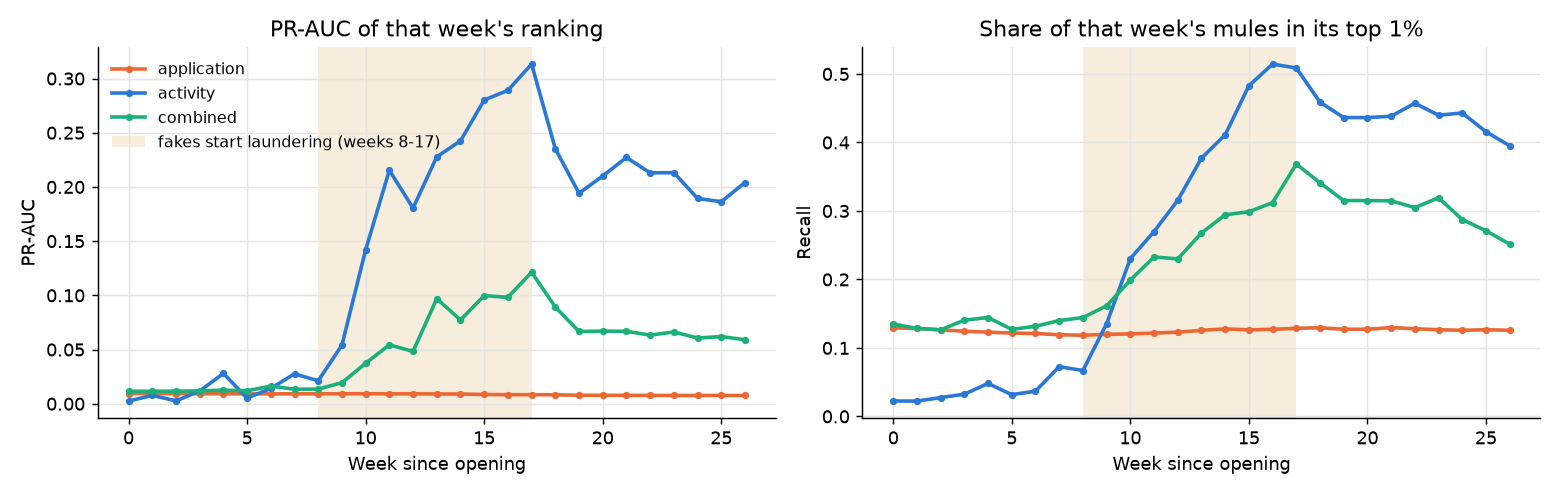

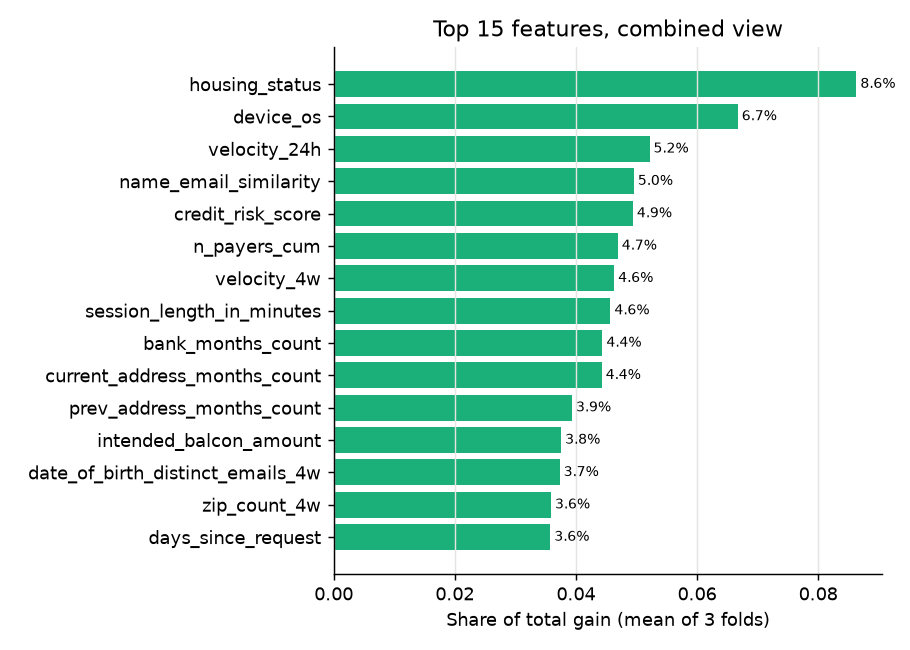

In [8]:
wk = by_week(oof)
FIGS = figures(str(REPORT), oof, folds, wk, imp)
if "ipykernel" in sys.modules:
    from IPython.display import Image, display
    for name in FIGS:
        display(Image(filename=str(REPORT / name)))

## 7. By week since opening, and feature importance

The weekly table answers the project's real question: **how early** can each view rank mules? Weeks before 8 can
only be won on application data (no laundering has started yet).

In [9]:
wk[wk["week"].isin([0, 1, 4, 8, 12, 17, 26])].pivot(index="week", columns="view", values="pr_auc").round(3)

view,activity,application,combined
week,,,
0,0.002,0.009,0.012
1,0.008,0.009,0.011
4,0.028,0.009,0.013
8,0.021,0.009,0.014
12,0.181,0.009,0.048
17,0.313,0.008,0.121
26,0.204,0.008,0.059


In [10]:
(imp[imp.view == "combined"].groupby("feature")["share"].mean().sort_values(ascending=False)
 .head(15).to_frame("share of gain").round(3))

,share of gain
feature,
housing_status,0.086
device_os,0.067
velocity_24h,0.052
name_email_similarity,0.050
credit_risk_score,0.049
n_payers_cum,0.047
velocity_4w,0.046
session_length_in_minutes,0.046
bank_months_count,0.044


## 8. Save

Writes `report.md`, `metrics_by_fold.csv`, `oof_by_week.csv`, `importance.csv` and the five figures to the report
folder.

**Things to check before tuning**
- If **combined** scores below **activity** alone, the model is overfitting the application columns: tune
  `min_child_samples`, `feature_fraction`, `reg_lambda` first.
- Rerun with `DROP = ["weeks_since_open"]`. A large drop means the model leans on the simulator's rule that fakes
  start in weeks 8 to 17.
- Look at the top-1% breakdown by type: catching only fakes is the known weakness of the application signal.

In [11]:
folds.to_csv(REPORT / "metrics_by_fold.csv", index=False)
wk.to_csv(REPORT / "oof_by_week.csv", index=False)
imp.to_csv(REPORT / "importance.csv", index=False)
settings = {"data": OUT, "weeks": list(WEEKS), "folds": [f"{t} -> {v}" for t, v in FOLDS], "dropped_features": DROP,
            "model": "LGBMClassifier(class_weight='balanced', deterministic=True), defaults otherwise", "seed": SEED,
            "lightgbm": lgb.__version__}
write_report(str(REPORT), settings, folds, wk, imp, FIGS)
print(f"saved to {REPORT} in {time.time() - t0:.0f}s")

saved to outputs/modelling/models/v1_full/lgbm_baseline in 35s
